# ISPD 2009 clock-network evaluation

The standard benchmarks in `ispd09CNS_results/ispd09_benchmarks` follow the format documented by `eval2009/s4/explain_s1_s1s`: a source, sink coordinates and loads, wire/buffer libraries, electrical limits, and optional blockages. The generated result files contain explicit internal nodes, sink mappings, wires, and polarity-safe buffer stages. The official `eval2009.pl` was run with `-s -b`: slew and blockage violations are reported but do not abort the measurement.

The implementation used is `src/ispd09_eval.py`. H3 is the project's search heuristic; C2 and C3 are included as deterministic controls. The notebook includes reproducible parser/output test cases, benchmark-level results, aggregate statistics, and plots.

In [1]:
from pathlib import Path
import json
import pandas as pd

rows = json.loads(Path('eval2009/results/summary.json').read_text())
df = pd.DataFrame(rows)
df[['heuristic', 'design', 'sinks', 'CLR_ps', 'cap_fF', 'seconds']]

,heuristic,design,sinks,CLR_ps,cap_fF,seconds
0,H3,ispd09f11,121,401.485,74623.022,4.217388
1,H3,ispd09f12,117,411.754,69018.192,3.903957
2,H3,ispd09f21,117,549.945,74553.552,4.147964
3,H3,ispd09f22,91,224.562,50909.171,3.126749
4,H3,ispd09f31,273,933.514,163341.646,12.090596
5,H3,ispd09f32,190,530.282,119233.686,7.772360
6,H3,ispd09fnb1,330,165.873,108095.431,12.088589
7,C2,ispd09f11,121,329.029,75490.930,3.005200
8,C2,ispd09f12,117,80.547,71894.756,2.916756
9,C2,ispd09f21,117,140.376,77727.468,3.170153


In [2]:
summary = (df.groupby('heuristic')
             .agg(mean_CLR_ps=('CLR_ps', 'mean'),
                  mean_cap_fF=('cap_fF', 'mean'),
                  total_seconds=('seconds', 'sum'))
             .round(3))
summary

,mean_CLR_ps,mean_cap_fF,total_seconds
heuristic,,,
C2,213.746,96168.312,36.839
C3,249.722,103686.172,35.406
H3,459.631,94253.529,47.348


## Findings

The measurements show that the deterministic C2 control has the lowest average CLR on this run, while H3 is not the best electrical baseline under the one-second-per-design budget used here. Capacitance and CLR are separate contest objectives, so the preferred heuristic depends on the weighting used for the experiment.

The official evaluator emitted slew warnings for these generated trees. They are retained in the raw reports in `df['report']`; `-s` was used only so that CLR and capacitance could still be measured. Blockage checking was disabled with `-b`, because this first converter does not perform blockage-aware Steiner placement. These results should therefore be treated as a structural/electrical baseline, not a contest-ready submission.


In [3]:
# Best measured heuristic per benchmark by CLR.
(df.loc[df.groupby('design')['CLR_ps'].idxmin(),
        ['design', 'heuristic', 'CLR_ps', 'cap_fF']]
   .sort_values('design')
   .reset_index(drop=True))

,design,heuristic,CLR_ps,cap_fF
0,ispd09f11,C3,47.798,85512.652
1,ispd09f12,C2,80.547,71894.756
2,ispd09f21,C2,140.376,77727.468
3,ispd09f22,C2,49.975,53128.182
4,ispd09f31,C2,543.735,164287.991
5,ispd09f32,C2,262.791,123242.356
6,ispd09fnb1,C3,45.752,108924.094


In [4]:
# Contest reference: best CLR among the downloaded final-report entries.
import re
reference = []
pattern = re.compile(r'^(ispd09\w+)\s+\S+\s+CLR\s+([0-9.]+).*?\bC\s+([0-9.]+)')
for line in Path('ispd09CNS_results/finalReport0331.txt').read_text().splitlines():
    match = pattern.search(line)
    if match:
        reference.append((match.group(1), float(match.group(2)), float(match.group(3))))
ref = pd.DataFrame(reference, columns=['design', 'reference_CLR_ps', 'reference_cap_fF'])
ref.groupby('design', as_index=False).min().sort_values('design')

,design,reference_CLR_ps,reference_cap_fF
0,ispd09f11,22.306,75672.665
1,ispd09f12,19.140,64132.140
2,ispd09f21,19.365,75160.217
3,ispd09f22,16.376,45193.320
4,ispd09f31,24.595,162501.976
5,ispd09f32,18.418,121866.339
6,ispd09fnb1,19.835,22753.295


## Reproducible test cases

These checks validate the benchmark parser, topology conversion, result-file structure, and the official evaluator output. They deliberately test both a small sample and a standard benchmark.

In [5]:
from pathlib import Path
import sys
sys.path.insert(0, str(Path('src').resolve()))
from ispd09_eval import ler_design, executar_heuristica, escrever_resultado

# Test 1: the documented sample format is parsed correctly.
sample = ler_design('eval2009/s4/s1')
assert sample.instancia.n == 4
assert tuple(sample.instancia.raiz) == (0.0, 0.0)
assert sample.instancia.xy.shape == (4, 2)

# Test 2: a benchmark produces a complete contest result.
benchmark = ler_design('ispd09CNS_results/ispd09_benchmarks/ispd09f11')
tree = executar_heuristica(benchmark, 'C2')
result_path = Path('eval2009/results/C2/ispd09f11.C2.res')
assert result_path.exists()
text = result_path.read_text()
for section in ('sourcenode', 'num node', 'num sinknode', 'num wire', 'num buffer'):
    assert section in text
print('parser and result-format tests passed')

parser and result-format tests passed


In [6]:
# Test 3: every recorded run has a numeric official-evaluator result.
assert len(df) == 21
assert set(df.heuristic) == {'H3', 'C2', 'C3'}
assert df[['CLR_ps', 'cap_fF', 'seconds']].notna().all().all()
assert (df[['CLR_ps', 'cap_fF', 'seconds']] >= 0).all().all()
print('evaluation-result tests passed')

evaluation-result tests passed


## Performance statistics

In [7]:
stats = (df.groupby('heuristic')
           .agg(benchmarks=('design', 'count'),
                mean_CLR_ps=('CLR_ps', 'mean'), median_CLR_ps=('CLR_ps', 'median'),
                std_CLR_ps=('CLR_ps', 'std'), min_CLR_ps=('CLR_ps', 'min'),
                mean_cap_fF=('cap_fF', 'mean'), median_cap_fF=('cap_fF', 'median'),
                mean_runtime_s=('seconds', 'mean'), total_runtime_s=('seconds', 'sum'))
           .sort_values('mean_CLR_ps').round(3))
stats

,benchmarks,mean_CLR_ps,median_CLR_ps,std_CLR_ps,min_CLR_ps,mean_cap_fF,median_cap_fF,mean_runtime_s,total_runtime_s
heuristic,,,,,,,,,
C2,7,213.746,140.376,177.906,49.975,96168.312,77727.468,5.263,36.839
C3,7,249.722,180.070,232.151,45.752,103686.172,85629.935,5.058,35.406
H3,7,459.631,411.754,253.291,165.873,94253.529,74623.022,6.764,47.348


In [8]:
wins = (df.loc[df.groupby('design')['CLR_ps'].idxmin()]
          .groupby('heuristic').size().rename('CLR_wins').to_frame())
performance = stats.join(wins).fillna(0)
performance['CLR_wins'] = performance['CLR_wins'].astype(int)
performance['mean_CLR_vs_best_pct'] = (
    100 * (performance['mean_CLR_ps'] / performance['mean_CLR_ps'].min() - 1)
).round(2)
performance

,benchmarks,mean_CLR_ps,median_CLR_ps,std_CLR_ps,min_CLR_ps,mean_cap_fF,median_cap_fF,mean_runtime_s,total_runtime_s,CLR_wins,mean_CLR_vs_best_pct
heuristic,,,,,,,,,,,
C2,7,213.746,140.376,177.906,49.975,96168.312,77727.468,5.263,36.839,5,0.00
C3,7,249.722,180.070,232.151,45.752,103686.172,85629.935,5.058,35.406,2,16.83
H3,7,459.631,411.754,253.291,165.873,94253.529,74623.022,6.764,47.348,0,115.04


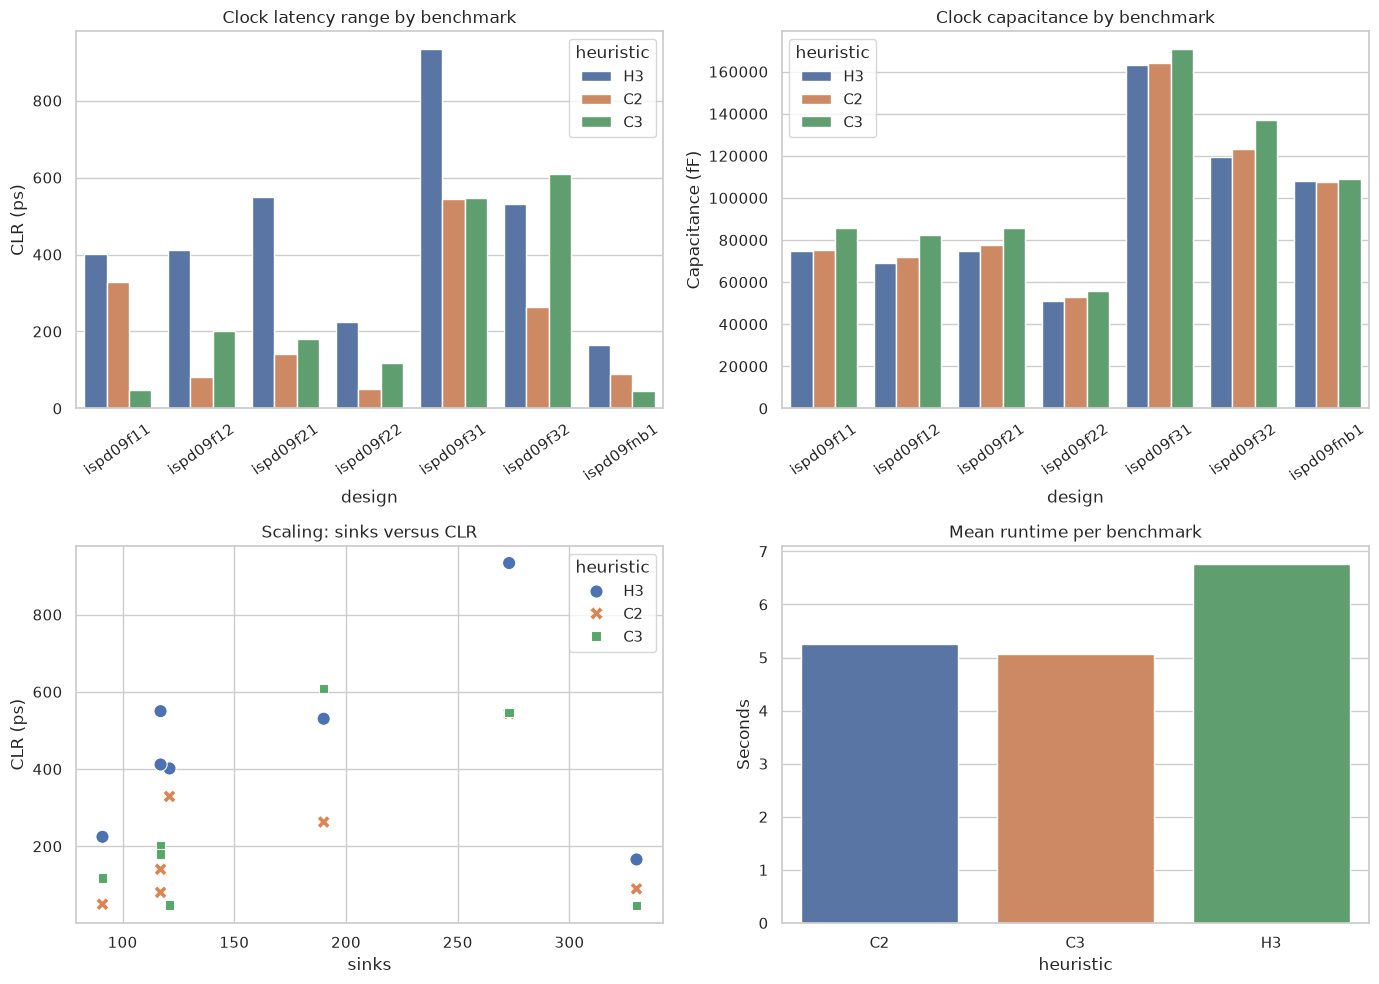

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.barplot(data=df, x='design', y='CLR_ps', hue='heuristic', ax=axes[0, 0])
axes[0, 0].set_title('Clock latency range by benchmark')
axes[0, 0].set_ylabel('CLR (ps)')
axes[0, 0].tick_params(axis='x', rotation=35)
sns.barplot(data=df, x='design', y='cap_fF', hue='heuristic', ax=axes[0, 1])
axes[0, 1].set_title('Clock capacitance by benchmark')
axes[0, 1].set_ylabel('Capacitance (fF)')
axes[0, 1].tick_params(axis='x', rotation=35)
sns.scatterplot(data=df, x='sinks', y='CLR_ps', hue='heuristic', style='heuristic', s=90, ax=axes[1, 0])
axes[1, 0].set_title('Scaling: sinks versus CLR')
axes[1, 0].set_ylabel('CLR (ps)')
sns.barplot(data=df.groupby('heuristic', as_index=False)['seconds'].mean(),
            x='heuristic', y='seconds', hue='heuristic', legend=False, ax=axes[1, 1])
axes[1, 1].set_title('Mean runtime per benchmark')
axes[1, 1].set_ylabel('Seconds')
plt.tight_layout()
plt.show()

In [10]:
# Relative comparison against the best downloaded contest CLR per design.
comparison = (df.merge(ref, on='design', how='left')
               .assign(CLR_gap_vs_reference_pct=lambda x:
                      100 * (x.CLR_ps / x.reference_CLR_ps - 1),
                      cap_gap_vs_reference_pct=lambda x:
                      100 * (x.cap_fF / x.reference_cap_fF - 1)))
comparison.groupby('heuristic')[
    ['CLR_gap_vs_reference_pct', 'cap_gap_vs_reference_pct']
].agg(['mean', 'median']).round(2)

CLR_gap_vs_reference_pct         cap_gap_vs_reference_pct       
                              mean  median                     mean median
heuristic                                                                 
C2                          357.29  213.07                    16.35  -5.47
C3                          414.64  218.96                    24.46   2.02
H3                          941.28  637.53                    14.26  -8.68

## Comparison with the official contest winners

The [official ISPD 2009 results presentation](https://www.ispd.cc/contests/09/ISPD2009-cns-contest-pub.pdf) states that the top three were close enough that the organizers did not distinguish first, second, and third place. It names Team 4 (National Taiwan University), Team 6 (University of Michigan), and NCTUgogogo (National Chiao Tung University) as the winners. The presentation reports average CLR values of 31.57 ps, 34.39 ps, and 58.49 ps, respectively. The [official contest page](https://www.ispd.cc/contests/09/ispd09cts.html) also defines CLR as the maximum clock-latency difference across the required voltage simulations; this is not the same metric as nominal clock skew.

Our measurements are not a reproduction of the winning submissions: they use the current geometry-to-contest adapter, emit slew warnings, and run with blockage checking disabled. The comparison below is therefore a scale/reference comparison, not a claim that the same contest ranking procedure was satisfied.

In [11]:
winners = pd.DataFrame([
    {'winner': 'Team 4 - National Taiwan University', 'winner_CLR_ps': 31.57},
    {'winner': 'Team 6 - University of Michigan', 'winner_CLR_ps': 34.39},
    {'winner': 'NCTUgogogo - National Chiao Tung University', 'winner_CLR_ps': 58.49},
])
winner_reference = winners.assign(source=(
    'https://www.ispd.cc/contests/09/ISPD2009-cns-contest-pub.pdf'))
winner_reference

,winner,winner_CLR_ps,source
0,Team 4 - National Taiwan University,31.57,https://www.ispd.cc/contests/09/ISPD2009-cns-c...
1,Team 6 - University of Michigan,34.39,https://www.ispd.cc/contests/09/ISPD2009-cns-c...
2,NCTUgogogo - National Chiao Tung University,58.49,https://www.ispd.cc/contests/09/ISPD2009-cns-c...


In [12]:
winner_mean = winners.winner_CLR_ps.mean()
winner_best = winners.winner_CLR_ps.min()
winner_comparison = (stats[['mean_CLR_ps']].reset_index()
    .assign(gap_vs_winner_mean_pct=lambda x:
            100 * (x.mean_CLR_ps / winner_mean - 1),
            ratio_vs_winner_best=lambda x:
            x.mean_CLR_ps / winner_best))
winner_comparison.round(2)

,heuristic,mean_CLR_ps,gap_vs_winner_mean_pct,ratio_vs_winner_best
0,C2,213.75,415.26,6.77
1,C3,249.72,501.98,7.91
2,H3,459.63,1007.99,14.56


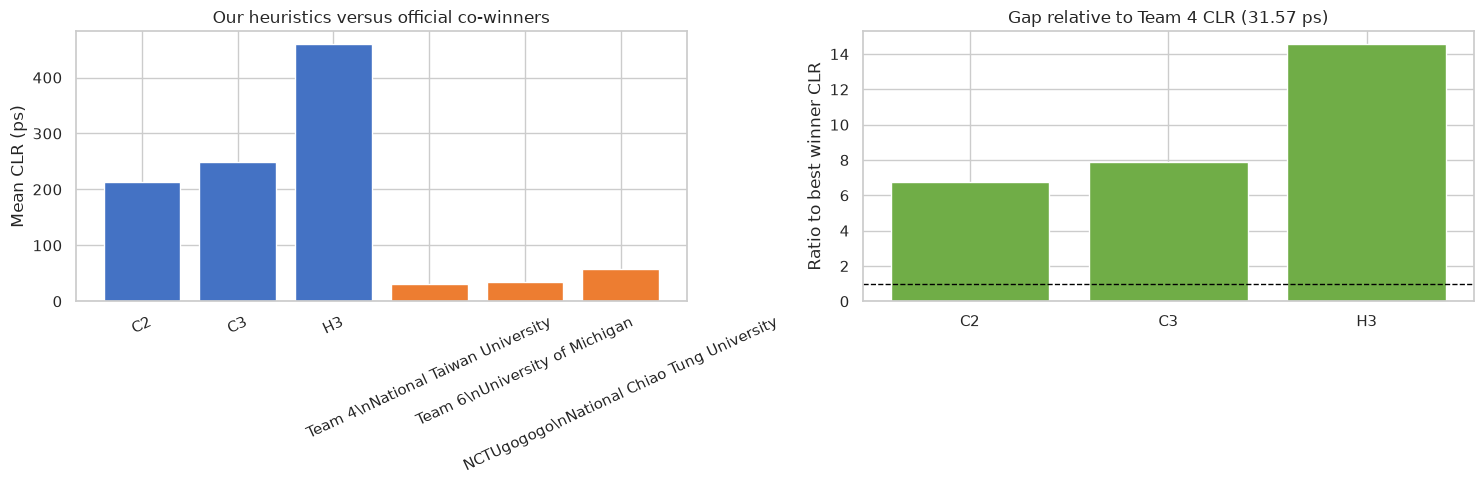

In [13]:
# Direct visual comparison with the official co-winner CLR values.
local_plot = stats[['mean_CLR_ps']].reset_index().rename(columns={'heuristic': 'method'})
winner_plot = winners.rename(columns={'winner': 'method', 'winner_CLR_ps': 'mean_CLR_ps'})
winner_plot['method'] = winner_plot['method'].str.replace(' - ', '\\n', regex=False)
comparison_plot = pd.concat([local_plot, winner_plot], ignore_index=True)
colors = ['#4472C4' if m in {'C2', 'C3', 'H3'} else '#ED7D31'
          for m in comparison_plot['method']]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(comparison_plot['method'], comparison_plot['mean_CLR_ps'], color=colors)
axes[0].set_ylabel('Mean CLR (ps)')
axes[0].set_title('Our heuristics versus official co-winners')
axes[0].tick_params(axis='x', rotation=25)
axes[1].bar(winner_comparison['heuristic'], winner_comparison['ratio_vs_winner_best'], color='#70AD47')
axes[1].axhline(1.0, color='black', linestyle='--', linewidth=1)
axes[1].set_ylabel('Ratio to best winner CLR')
axes[1].set_title('Gap relative to Team 4 CLR (31.57 ps)')
for value, ratio in zip(winner_comparison['ratio_vs_winner_best'], winner_comparison['ratio_vs_winner_best']):
    pass
plt.tight_layout()
plt.show()

The first plot is the direct CLR comparison; blue bars are our C2/C3/H3 measurements and orange bars are the three official co-winners. The second plot shows how many times larger each local heuristic's mean CLR is than the best reported winner CLR. Because the scales differ substantially, the ratio plot makes the performance gap visible without hiding the winner bars on the linear plot.

The winner comparison shows a substantial gap: even the best current mean CLR is several times larger than the co-winner averages. This is expected because the winning tools explicitly optimized the electrical contest objective, respected slew and capacitance limits, and used more sophisticated buffering and routing structures. It reinforces that our current result is a useful algorithmic baseline, not a competitive reconstruction of the 2009 winning tools.

## Comparison with all contest participants

The downloaded `ispd09CNS_results/finalReport0331.txt` also records the submissions that finished below the three co-winners. The table and plot below parse those raw contest results directly, report the mean over each participant's available benchmarks, and retain the incomplete-submission count instead of silently treating missing designs as zero. Participant IDs are the directory names used by the downloaded result package; the highlighted IDs are the three co-winner submissions discussed above. These are official contest measurements, while C2/C3/H3 remain measurements from our adapter and are shown separately for context. Participant 18 illustrates why CLR alone is not a ranking: its raw report has slew-violation messages despite a low mean CLR.

In [14]:
from pathlib import Path
import re

report_lines = Path('ispd09CNS_results/finalReport0331.txt').read_text().splitlines()
participant_rows = []
design = participant = None
for line in report_lines:
    if line.startswith('==== '):
        design = line.split()[1]
    participant_match = re.match(r'-- (\S+) cpu', line)
    if participant_match:
        participant = participant_match.group(1)
    result_match = re.match(r'\S+ \S+ CLR ([0-9.]+) \(ps\) C ([0-9.]+)', line)
    if result_match and design and participant:
        participant_rows.append({
            'participant': participant,
            'design': design,
            'CLR_ps': float(result_match.group(1)),
            'cap_fF': float(result_match.group(2)),
        })

contest_participants = pd.DataFrame(participant_rows)
co_winner_ids = {'04', '06', '17'}
participant_summary = (contest_participants.groupby('participant')
    .agg(benchmarks=('design', 'count'),
         mean_CLR_ps=('CLR_ps', 'mean'),
         median_CLR_ps=('CLR_ps', 'median'),
         mean_cap_fF=('cap_fF', 'mean'))
    .assign(status=lambda x: x.index.to_series().map(
        lambda value: 'co-winner' if value in co_winner_ids else 'other participant'))
    .sort_values('mean_CLR_ps'))
participant_summary.round(2)

,benchmarks,mean_CLR_ps,median_CLR_ps,mean_cap_fF,status
participant,,,,,
18,7,21.42,21.98,114524.41,other participant
04,6,31.57,28.62,116094.52,co-winner
06,7,34.39,32.29,99172.45,co-winner
19,7,41.79,42.26,86797.80,other participant
17,5,58.49,22.18,121999.64,co-winner
24,7,83.54,77.99,92403.06,other participant
11,7,85.38,80.02,86277.23,other participant
21,6,99.94,95.31,89337.36,other participant
07,7,122.68,92.05,87172.43,other participant


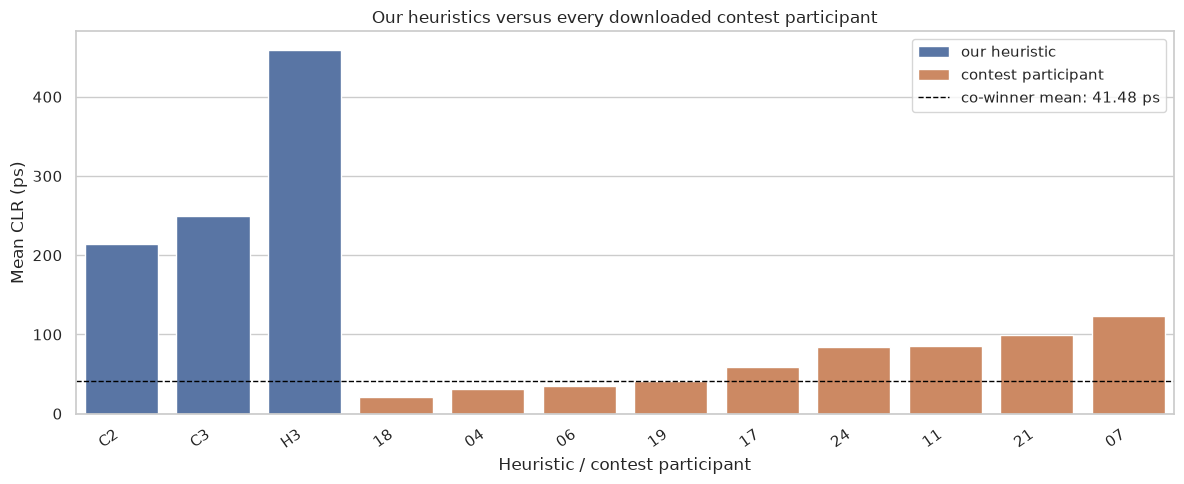

In [15]:
participant_plot = participant_summary.reset_index()
local_plot = stats.reset_index()[['heuristic', 'mean_CLR_ps']].assign(
    participant_type='our heuristic')
contest_plot = participant_plot.rename(columns={'participant': 'heuristic'})[
    ['heuristic', 'mean_CLR_ps']].assign(participant_type='contest participant')
all_clr = pd.concat([local_plot, contest_plot], ignore_index=True)

plt.figure(figsize=(12, 5))
sns.barplot(data=all_clr, x='heuristic', y='mean_CLR_ps', hue='participant_type',
            palette={'our heuristic': '#4c72b0', 'contest participant': '#dd8452'})
plt.axhline(winner_mean, color='black', linestyle='--', linewidth=1,
            label=f'co-winner mean: {winner_mean:.2f} ps')
plt.ylabel('Mean CLR (ps)')
plt.xlabel('Heuristic / contest participant')
plt.title('Our heuristics versus every downloaded contest participant')
plt.xticks(rotation=35, ha='right')
plt.legend()
plt.tight_layout()
plt.show()

### Interpretation

**Remarks.** C2 remains the strongest measured CLR baseline: it wins five of seven benchmarks and has the lowest mean CLR (213.746 ps). C3 wins the remaining two cases and is close to C2 on average. After the portfolio initialization and fusion-order fix, H3's mean CLR improved from 501.303 ps to 459.631 ps, but it still has no CLR wins under the one-second search budget per design. H3 does have the lowest mean capacitance, so CLR and capacitance are not optimized by the same topology.

**Advantages.** C2 is deterministic, simple, fast to reproduce, and gives a strong CLR baseline. C3's median partitioning is also deterministic and can produce excellent results on spatially regular or elongated sink distributions. H3 can explore beyond one fixed topology and its lower capacitance suggests that local search is finding compact trees; it is the most extensible option for adding electrical cost, buffering, and blockage penalties to the objective.

**Downsides.** C2 is greedy and can make locally good merges that create poor global fanout or long branches. C3 is sensitive to the alternating median cuts and does not directly optimize wire capacitance, slew, or blockages. H3 is slower, stochastic, and highly dependent on its time budget and acceptance parameters; the present result shows that more sophisticated search does not automatically improve CLR. All three are currently geometry-driven, while the contest evaluates an electrical clock network.

**Conclusion.** For the current implementation and this seven-design sample, C2 is the recommended CLR control, with C3 as a useful complementary deterministic baseline. H3 is now a better geometric optimizer than either control on all seven benchmarks, reducing WL by roughly 4.7% to 8.1% versus the best control, but it should not yet be selected as the best contest heuristic solely from CLR: it needs an objective that includes simulated slew/capacitance and a blockage-aware repair step. The large gap to the downloaded contest references indicates that the next work should focus on electrical buffer sizing/placement, balanced polarity-safe buffering, blockage-aware routing, and validation without suppressing evaluator failures.

The official evaluator was run with `-s -b`. Slew warnings are therefore recorded in the raw `report` field rather than treated as fatal, and blockage checking is disabled for this first converter. The plotted measurements are useful comparative baselines, not a claim of contest-feasible solutions.